In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split


In [5]:
from sklearn.preprocessing import StandardScaler


In [9]:
from sklearn.svm import SVC
from sklearn.metrics import classification_report,confusion_matrix


In [10]:
df=pd.read_csv("UniversalBank.csv")
df.head(5)

,ID,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
0,1,25,1,49,91107,4,1.6,1,0,0,1,0,0,0
1,2,45,19,34,90089,3,1.5,1,0,0,1,0,0,0
2,3,39,15,11,94720,1,1.0,1,0,0,0,0,0,0
3,4,35,9,100,94112,1,2.7,2,0,0,0,0,0,0
4,5,35,8,45,91330,4,1.0,2,0,0,0,0,0,1


In [12]:
df.describe(include="all")

,ID,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.00000,5000.000000,5000.000000
mean,2500.500000,45.338400,20.104600,73.774200,93152.503000,2.396400,1.937913,1.881000,56.498800,0.096000,0.104400,0.06040,0.596800,0.294000
std,1443.520003,11.463166,11.467954,46.033729,2121.852197,1.147663,1.747666,0.839869,101.713802,0.294621,0.305809,0.23825,0.490589,0.455637
min,1.000000,23.000000,-3.000000,8.000000,9307.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000
25%,1250.750000,35.000000,10.000000,39.000000,91911.000000,1.000000,0.700000,1.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000
50%,2500.500000,45.000000,20.000000,64.000000,93437.000000,2.000000,1.500000,2.000000,0.000000,0.000000,0.000000,0.00000,1.000000,0.000000
75%,3750.250000,55.000000,30.000000,98.000000,94608.000000,3.000000,2.500000,3.000000,101.000000,0.000000,0.000000,0.00000,1.000000,1.000000
max,5000.000000,67.000000,43.000000,224.000000,96651.000000,4.000000,10.000000,3.000000,635.000000,1.000000,1.000000,1.00000,1.000000,1.000000


In [14]:
df.dtypes

ID                      int64
Age                     int64
Experience              int64
Income                  int64
ZIP Code                int64
Family                  int64
CCAvg                 float64
Education               int64
Mortgage                int64
Personal Loan           int64
Securities Account      int64
CD Account              int64
Online                  int64
CreditCard              int64
dtype: object

In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ID                  5000 non-null   int64  
 1   Age                 5000 non-null   int64  
 2   Experience          5000 non-null   int64  
 3   Income              5000 non-null   int64  
 4   ZIP Code            5000 non-null   int64  
 5   Family              5000 non-null   int64  
 6   CCAvg               5000 non-null   float64
 7   Education           5000 non-null   int64  
 8   Mortgage            5000 non-null   int64  
 9   Personal Loan       5000 non-null   int64  
 10  Securities Account  5000 non-null   int64  
 11  CD Account          5000 non-null   int64  
 12  Online              5000 non-null   int64  
 13  CreditCard          5000 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 547.0 KB


In [24]:
# remove columns
print(df.columns)
# df=df.drop(columns=['ID'])

Index(['Age', 'Experience', 'Income', 'ZIP Code', 'Family', 'CCAvg',
       'Education', 'Mortgage', 'Personal Loan', 'Securities Account',
       'CD Account', 'Online', 'CreditCard'],
      dtype='object')


In [25]:
df.isnull().sum()

Age                   0
Experience            0
Income                0
ZIP Code              0
Family                0
CCAvg                 0
Education             0
Mortgage              0
Personal Loan         0
Securities Account    0
CD Account            0
Online                0
CreditCard            0
dtype: int64

In [26]:
df=df.dropna(subset=['CreditCard'])

In [54]:
X=df.drop(columns=['CreditCard','ZIP Code'])

In [55]:
y=df['CreditCard']

In [56]:
x_train,x_test,y_train,y_test=train_test_split(X,y,test_size=0.25,random_state=42,stratify=y)
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(3750, 11)
(1250, 11)
(3750,)
(1250,)


In [46]:
scaler=StandardScaler()

In [57]:
x_train=scaler.fit_transform(x_train)
x_test=scaler.transform(x_test)


In [58]:
model=SVC(kernel="linear",random_state=42,class_weight='balanced')

model.fit(x_train,y_train)
y_pred=model.predict(x_test)

In [59]:
from sklearn.metrics import confusion_matrix,classification_report,precision_score,accuracy_score,r2_score
print("Accuracy:", accuracy_score(y_test, y_pred))

print("Precision:", precision_score(y_test, y_pred))

print("Classification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.7352
Precision: 0.78125
Classification Report:
               precision    recall  f1-score   support

           0       0.73      0.98      0.84       883
           1       0.78      0.14      0.23       367

    accuracy                           0.74      1250
   macro avg       0.76      0.56      0.54      1250
weighted avg       0.75      0.74      0.66      1250



In [60]:
print("Actual values:")
print(y_test.value_counts())

print("Predicted values:")
print(pd.Series(y_pred).value_counts())

Actual values:
CreditCard
0    883
1    367
Name: count, dtype: int64
Predicted values:
0    1186
1      64
Name: count, dtype: int64


In [41]:
print(y_train.value_counts())
print(y_test.value_counts())

CreditCard
0    2641
1    1109
Name: count, dtype: int64
CreditCard
0    889
1    361
Name: count, dtype: int64


In [51]:
print(confusion_matrix(y_test, y_pred))

[[869  14]
 [317  50]]


In [52]:
# display 
print(dir(plt))

['AbstractContextManager', 'Annotation', 'Arrow', 'Artist', 'AutoLocator', 'AxLine', 'Axes', 'BackendFilter', 'Button', 'Circle', 'Colorizer', 'ColorizingArtist', 'Colormap', 'Enum', 'ExitStack', 'Figure', 'FigureBase', 'FigureCanvasBase', 'FigureManagerBase', 'FixedFormatter', 'FixedLocator', 'FormatStrFormatter', 'Formatter', 'FuncFormatter', 'GridSpec', 'IndexLocator', 'Line2D', 'LinearLocator', 'Locator', 'LogFormatter', 'LogFormatterExponent', 'LogFormatterMathtext', 'LogLocator', 'MaxNLocator', 'MouseButton', 'MultipleLocator', 'Normalize', 'NullFormatter', 'NullLocator', 'PolarAxes', 'Polygon', 'Rectangle', 'ScalarFormatter', 'Slider', 'Subplot', 'SubplotSpec', 'TYPE_CHECKING', 'Text', 'TickHelper', 'Widget', '_ColorizerInterface', '_NO_PYPLOT_NOTE', '_REPL_DISPLAYHOOK', '_ReplDisplayHook', '__annotations__', '__builtins__', '__cached__', '__doc__', '__file__', '__loader__', '__name__', '__package__', '__spec__', '_add_pyplot_note', '_api', '_auto_draw_if_interactive', '_backend

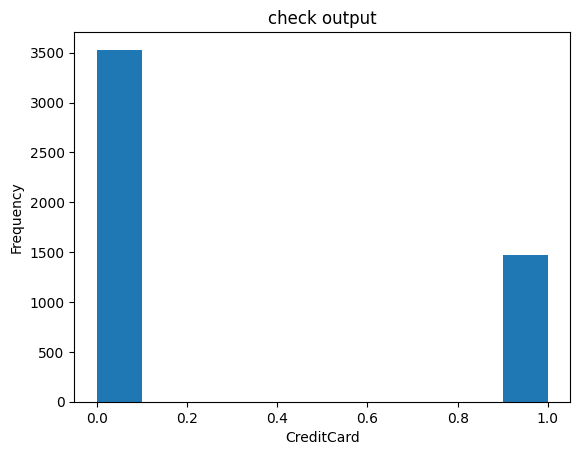

In [61]:
plt.hist(df['CreditCard'],bins=10)
plt.title("check output")
plt.xlabel("CreditCard")
plt.ylabel("Frequency")
plt.show()